# Setup

In [2]:
# from google.colab import files
# files.upload()

!pip install kagglehub


In [3]:
import kagglehub
from google.colab import userdata
import os
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

path = kagglehub.dataset_download("yash92328/ai4mars-terrainaware-autonomous-driving-on-mars")
print(path)

 52%|█████▏    | 2.99G/5.72G [00:36<00:33, 88.5MB/s]


KeyboardInterrupt: 

In [ ]:
import glob

MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
print("msl folder:", MSL)

EDR_DIR = os.path.join(MSL, "images", "edr")
MXY_DIR = os.path.join(MSL, "images", "mxy")
RNG_DIR = os.path.join(MSL, "images", "rng-30m")
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
print(os.listdir(os.path.join(MSL, "labels", "test")))

In [ ]:
TEST_LABEL_DIR = os.path.join(MSL, "labels", "test", "masked-gold-min3-100agree")

for name, d in [("edr", EDR_DIR), ("mxy", MXY_DIR), ("rng", RNG_DIR),
                ("train labels", TRAIN_LABEL_DIR), ("test labels", TEST_LABEL_DIR)]:
    files = sorted(os.listdir(d))
    print(f"{name}: {len(files)} files, e.g. {files[:2]}")

# Task #1: Random sample

In [ ]:
import random

train_labels = sorted(f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png"))
test_labels = sorted(f for f in os.listdir(TEST_LABEL_DIR) if f.endswith(".png"))

random.seed(42)
train_sample = random.sample(train_labels, 500)
test_sample = random.sample(test_labels, 125)

print(len(train_sample), "train", len(test_sample), "test")
print(train_sample[:3])
print(test_sample[:3])

In [ ]:
# Making sure we get the right amount of files, no duplicates, and that all the files are real train files

print(len(train_sample) == 500, len(test_sample) == 125) # checks if file amount is right
print(len(set(train_sample)) == 500) # checks for duplicates
print(all(f in train_labels for f in train_sample)) # checks if all train files are real

# Task #2: Check files, sizes, and label values

In [ ]:
def get_paths(label_file, split):
  """Given a label file name, return the paths to its photo, masks, and label."""
  base = label_file.replace(".png", "")
  if split == "test":
    base = base.replace("_merged", "")
    label_dir = TEST_LABEL_DIR
  else:
    label_dir = TRAIN_LABEL_DIR

  return {
      "edr":   os.path.join(EDR_DIR, base + ".JPG"),
      "mxy":   os.path.join(MXY_DIR, base.replace("EDR", "MXY") + ".png"),
      "rng":   os.path.join(RNG_DIR, base.replace("EDR", "RNG") + ".png"),
      "label": os.path.join(label_dir, label_file),
  }

print(get_paths(train_sample[0], "train"))
print(get_paths(test_sample[0], "test"))

In [ ]:
import numpy as np
from PIL import Image

ALLOWED = {0, 1, 2, 3, 255}

def check(label_file, split):
  """Return a list of problems with this image. An empty list means it passed."""
  paths = get_paths(label_file, split)

  # First check to make sure all the files exist
  problems = []
  for kind, p in paths.items():
    if not os.path.exists(p):
      problems.append(f"missing {kind}")
  if problems:
    return problems

  # Second check to mae sure all four are hte same size
  sizes = {kind: Image.open(p).size for kind, p in paths.items()}
  if len(set(sizes.values())) > 1:
    problems.append(f"size mismatch {sizes}")

  # Third check to make sure that the label only uses allowed values
  label = np.array(Image.open(paths["label"]))
  bad = set(np.unique(label).tolist()) - ALLOWED
  if bad:
    problems.append(f"bad label values {bad}")

  return problems

print(check(train_sample[0], "train"))

In [ ]:
# Just making sure checker can actually fail
print(check("NLA_FAKE123EDR_TEST.png", "train"))

In [ ]:
results = []
for split, sample in [("train", train_sample), ("test", test_sample)]:
  for f in sample:
    results.append({"split": split, "label_file": f, "problems": check(f, split)})

failed = [r for r in results if r["problems"]]
print(f"{len(failed)} of {len(results)} images failed")
for r in failed:
  print(r["split"], r["label_file"], r["problems"])

In [ ]:
import pandas as pd

rows = []
for r in results:
  paths = get_paths(r["label_file"], r["split"])
  row = {"split": r["split"]}
  for kind, p in paths.items():
    row[kind] = os.path.relpath(p, MSL)
  row["passed"] = len(r["problems"]) == 0
  rows.append(row)

df = pd.DataFrame(rows)
df.to_csv("sample_split.csv", index=False)
print(df.shape)
df.head()

**Result:** 0 of 625 sampled images failed. All have edr/mxy/rng/label files, matching sizes, and only label values {0, 1, 2, 3, 255}.

Note: the full dataset has 33 photos missing MXY masks and 34 missing RNG masks, but none landed in this sample.

# Task #3: Check images, create threshold

In [ ]:
# hey guys
import matplotlib.pyplot as plt

NULL_VALUE = 255

def labeled_fraction(label_file, split):
  """Return the fraction of pixels in a label that are NOT 255 (i.e. labeled)."""
  paths = get_paths(label_file, split)
  label = np.array(Image.open(paths["label"]))
  return (label != NULL_VALUE).sum() / label.size

# Test it on one image before running everything
# print(labeled_fraction(train_sample[0], "train"))

# Add label_file and labeled_frac to the df from Task #2
df["label_file"] = [r["label_file"] for r in results]
df["labeled_frac"] = [labeled_fraction(r["label_file"], r["split"]) for r in results]

print(df.groupby("split")["labeled_frac"].describe())

In [ ]:
# Plot 1: histogram of labeled fraction

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split in zip(axes, ["train", "test"]):
  vals = df.loc[df.split == split, "labeled_frac"]
  ax.hist(vals, bins=40, edgecolor="black")
  ax.set_title(f"{split} (n={len(vals)})")
  ax.set_xlabel("Fraction of pixels labeled")
axes[0].set_ylabel("Number of images")
plt.tight_layout()
plt.show()

In [ ]:
# Plot 2: how many images would each threshold drop?

thresholds = np.linspace(0, 1, 101)

plt.figure(figsize=(8, 5))
for split in ["train", "test"]:
  vals = df.loc[df.split == split, "labeled_frac"].values
  dropped = [(vals < t).mean() * 100 for t in thresholds]
  plt.plot(thresholds * 100, dropped, label=split)

plt.xlabel("Minimum % of pixels labeled (threshold)")
plt.ylabel("% of images dropped")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Apply the threshold

THRESHOLD = 0.10  # may change later

# Keep all test images; only filter train
df["keep"] = (df["split"] == "test") | (df["labeled_frac"] >= THRESHOLD)

print(df.groupby("split")["keep"].agg(kept="sum", total="count"))
print(f"Dropped: {(~df.keep).sum()} of {len(df)}")

df.to_csv("sample_split_filtered.csv", index=False)

df_kept = df[df.keep]
print(df_kept.shape)

# Task #4: Pixel Count

In [ ]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Load the dataset
path = kagglehub.dataset_download(
    "yash92328/ai4mars-terrainaware-autonomous-driving-on-mars"
)
MSL = glob.glob(os.path.join(path, "**", "msl"), recursive=True)[0]
TRAIN_LABEL_DIR = os.path.join(MSL, "labels", "train")
NULL_VALUE = 255

# Use the same 500-image training subset as Task 1
train_labels = sorted(
    f for f in os.listdir(TRAIN_LABEL_DIR) if f.endswith(".png")
)
random.seed(42)
train_sample = random.sample(train_labels, 500)

CLASSES = [0, 1, 2, 3]
CLASS_LABELS = ["soil", "bedrock", "sand", "big rock"]
N = len(train_sample)

pixel_counts = np.zeros(len(CLASSES), dtype=np.int64)
image_counts = np.zeros(len(CLASSES), dtype=np.int64)
heat = None
labeled_total = 0
resized = 0

In [ ]:
# Count pixels and images containing each class
for f in train_sample:
  with Image.open(os.path.join(TRAIN_LABEL_DIR, f)) as img:
    label = np.array(img)

  counts = np.bincount(label[label != NULL_VALUE], minlength=len(CLASSES))
  pixel_counts += counts
  image_counts += counts > 0
  labeled_total += (label != NULL_VALUE).sum()

  # Resize only for the heatmaps; pixel counts use the original size
  if heat is None:
    heat = np.zeros((len(CLASSES),) + label.shape)
  if label.shape != heat.shape[1:]:
    label = np.array(Image.fromarray(label).resize(
        (heat.shape[2], heat.shape[1]), resample=Image.NEAREST
    ))
    resized += 1

  for c in CLASSES:
    heat[c] += label == c

heat /= N

In [ ]:
# Sanity checks
assert pixel_counts.sum() == labeled_total
assert (image_counts <= N).all()
assert heat.min() >= 0 and heat.max() <= 1

print(f"{N} training images, heatmap size {heat.shape[1]}x{heat.shape[2]}, {resized} masks resized")

# Class summary (excluding void/null pixels)
summary = pd.DataFrame({
    "class": CLASS_LABELS,
    "pixels": pixel_counts,
    "% of labeled pixels": (
        pixel_counts / max(labeled_total, 1) * 100
    ).round(2),
    "images with class": image_counts,
    "% of images": (image_counts / N * 100).round(1),
})
print(summary.to_string(index=False))

# Heatmaps: fraction of sampled images with each class at each position
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, c in zip(axes.flat, CLASSES):
  im = ax.imshow(heat[c], cmap="Blues", vmin=0, vmax=1, origin="upper")
  ax.set_title(CLASS_LABELS[c])
  ax.axis("off")
  fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="fraction of images")

plt.tight_layout()
plt.show()

# Task #6 and # 7 : Map Class to more Distrinct Colors

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

target_size = (512, 512)

color_map = {
    0 : [255, 0, 0],
    1 : [255, 255, 0],
    2 : [0, 255, 0],
    3 : [0, 255, 255],
    255 : [0, 0, 255],
}

class_names = {
    0 : "soil",
    1 : "bedrock",
    2 : "sand",
    3 : "Big Rock",
    255 :"void/null"
}

def load_and_resize (edr_path,label_path, target_size = target_size):
    edr_image = Image.open(edr_path).convert('L')
    edr_resized = edr_image.resize(target_size, resample = Image.BILINEAR)
    edr_arr = np.array(edr_resized)

    label_img = Image.open(label_path)
    label_resized = label_img.resize(target_size , resample = Image.NEAREST)
    label_arr = np.array(label_resized)

    return edr_arr, label_arr

def colorize_mask (label_arr):
    colored_mask = np.zeros((512, 512, 3), dtype = np.uint8)

    for class_ids, colors in color_map.items() :
        colored_mask[label_arr == class_ids] = colors
    return colored_mask

sample = df_kept.iloc[0]
sample_edr = os.path.join(MSL, sample['edr'])
sample_label = os.path.join(MSL, sample['label'])

edr_arr, label_arr = load_and_resize(sample_edr, sample_label)
colored_mask = colorize_mask(label_arr)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(edr_arr, cmap='gray')
axes[0].set_title(f"Input EDR ({target_size[0]}x{target_size[1]})")
axes[0].axis('off')

axes[1].imshow(colored_mask)
axes[1].set_title("Colored Segmentation Mask")
axes[1].axis('off')

plt.tight_layout()
plt.show()


In [6]:
import os
import zipfile
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

local_extract_path = '/content/ai4mars_subset'
os.makedirs(local_extract_path, exist_ok=True)

zip_drive_path = '/content/drive/MyDrive/AI4Mars_Subset/ai4mars_subset.zip'
if len(os.listdir(local_extract_path)) == 0:
    print("Extracting subset from Google Drive... This is much faster than downloading the full dataset!")
    with zipfile.ZipFile(zip_drive_path, 'r') as zip_ref:
        zip_ref.extractall(local_extract_path)
    print("Extraction complete!")
else:
    print("Subset already extracted locally.")

MSL = local_extract_path
print("MSL root path is now set to:", MSL)

df_kept = pd.read_csv('/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv')
print(f"Loaded metadata successfully. Total active samples: {len(df_kept)}")

Mounted at /content/drive
Extracting subset from Google Drive... This is much faster than downloading the full dataset!
Extraction complete!
MSL root path is now set to: /content/ai4mars_subset
Loaded metadata successfully. Total active samples: 839


# DeepLabV3 Resnet50 Training

In [7]:
# Imports, settings, and the train / validation tables
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch"], check=True)
import segmentation_models_pytorch as smp

import os
import pandas as pd
import torch, torch.nn as nn
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from IPython.display import clear_output
from matplotlib.ticker import MaxNLocator

IMG_SIZE = (256, 256)   # must be a multiple of 32; lower it (e.g. 224) if you run out of GPU memory
NUM_CLASSES = 4         # soil, bedrock, sand, big rock
IGNORE = 255            # unlabeled pixels are skipped in the loss
BATCH = 16
LR = 0.001
EPOCHS = 20
CLASS_NAMES = ["soil", "bedrock", "sand", "big rock"]

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime > Change runtime type > pick a GPU.")

# Restore MSL path if lost
MSL = "/content/ai4mars_subset"

# Automatically reload df_kept if it was cleared from the kernel memory
try:
    df_kept
except NameError:
    print("df_kept was missing from memory. Reloading it from your Google Drive CSV...")
    df_kept = pd.read_csv("/content/drive/MyDrive/AI4Mars_Subset/sample_split_filtered.csv")

if "keep" in df_kept.columns:
    df_kept = df_kept[df_kept["keep"] == True]
train_df = df_kept[df_kept["split"] == "train"].reset_index(drop=True)
val_df = df_kept[df_kept["split"] == "test"].reset_index(drop=True).copy()

# Validation masks = min2. Same image names as min3, just in the min2 label folder.
val_df["label"] = val_df["label"].str.replace("min3-100agree", "min2-100agree", regex=False)
assert "min2-100agree" in val_df["label"].iloc[0], "Label paths don't contain 'min3-100agree'; check the label column."

has_min2 = val_df["label"].apply(lambda p: os.path.exists(os.path.join(MSL, p)))
if not has_min2.all():
    print(f"WARNING: {(~has_min2).sum()} of {len(val_df)} validation images have no min2 mask on disk; dropping them")
val_df = val_df[has_min2].reset_index(drop=True)
assert len(val_df) > 0, (
    "No min2 masks found. Your Drive subset probably only has labels/test/masked-gold-min3-100agree. "
    "Copy labels/test/masked-gold-min2-100agree from the Kaggle download into the subset."
)
print(f"train {len(train_df)} | validation (min2 masks) {len(val_df)}")

device: cuda
train 714 | validation (min2 masks) 125


In [10]:
# Dataset + loaders
from PIL import Image
import os
import numpy as np

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class Mars(Dataset):
    def __init__(self, df):
        self.df = df
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        # EDR is grayscale; copy it to 3 channels for the pretrained ResNet
        img = Image.open(os.path.join(MSL, row["edr"])).convert("RGB").resize(IMG_SIZE, Image.BILINEAR)
        lab = Image.open(os.path.join(MSL, row["label"])).resize(IMG_SIZE, Image.NEAREST)  # nearest keeps class ids
        img = TF.normalize(TF.to_tensor(img), MEAN, STD)
        return img, torch.from_numpy(np.array(lab)).long()

pin = device == "cuda"
train_dl = DataLoader(Mars(train_df), batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=pin, drop_last=True)
val_dl = DataLoader(Mars(val_df), batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=pin)

xb, yb = next(iter(train_dl))   # quick check that loading works
print("batch:", tuple(xb.shape), tuple(yb.shape), "| label values:", torch.unique(yb).tolist())

batch: (16, 3, 256, 256) (16, 256, 256) | label values: [0, 1, 2, 3, 255]


In [11]:
# Cell 3: Model, loss, optimizer
model = smp.DeepLabV3(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
    activation="softmax2d",    # softmax over the class dimension: the model outputs probabilities
).to(device)

# The model already outputs probabilities, so categorical cross-entropy is the negative
# log of the probability of the true class (NLLLoss on log-probabilities).
nll = nn.NLLLoss(ignore_index=IGNORE)
def cce(probs, target):
    return nll(torch.log(probs + 1e-7), target)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

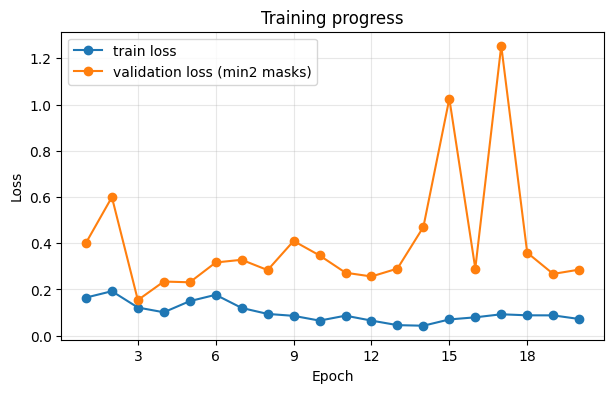

epoch 01 | train loss 0.1650 | val loss 0.4012
epoch 02 | train loss 0.1926 | val loss 0.5994
epoch 03 | train loss 0.1220 | val loss 0.1542
epoch 04 | train loss 0.1014 | val loss 0.2344
epoch 05 | train loss 0.1496 | val loss 0.2312
epoch 06 | train loss 0.1771 | val loss 0.3168
epoch 07 | train loss 0.1202 | val loss 0.3285
epoch 08 | train loss 0.0943 | val loss 0.2839
epoch 09 | train loss 0.0860 | val loss 0.4098
epoch 10 | train loss 0.0654 | val loss 0.3474
epoch 11 | train loss 0.0867 | val loss 0.2726
epoch 12 | train loss 0.0655 | val loss 0.2563
epoch 13 | train loss 0.0458 | val loss 0.2904
epoch 14 | train loss 0.0433 | val loss 0.4703
epoch 15 | train loss 0.0705 | val loss 1.0254
epoch 16 | train loss 0.0796 | val loss 0.2904
epoch 17 | train loss 0.0928 | val loss 1.2544
epoch 18 | train loss 0.0883 | val loss 0.3592
epoch 19 | train loss 0.0881 | val loss 0.2674
epoch 20 | train loss 0.0724 | val loss 0.2859
saved model locally to deeplabv3_smp.pt
Copied model checkpo

In [14]:
# Cell 4: Train, with a loss graph that updates after every epoch
import matplotlib.pyplot as plt
train_losses, val_losses, log = [], [], []

def plot_progress():
    clear_output(wait=True)
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, train_losses, marker="o", label="train loss")
    plt.plot(epochs, val_losses, marker="o", label="validation loss (min2 masks)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training progress")
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.grid(alpha=0.3)
    plt.legend()
    plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("\n".join(log))

for epoch in range(1, EPOCHS + 1):
    # train
    model.train()
    total, n = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = cce(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
        n += x.size(0)
    train_losses.append(total / n)

    # validate on the min2 masks
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(device), y.to(device)
            loss = cce(model(x), y).item()
            if np.isfinite(loss):          # a batch with no labeled pixels gives NaN; skip it
                total += loss * x.size(0)
                n += x.size(0)
    val_losses.append(total / max(n, 1))

    log.append(f"epoch {epoch:02d} | train loss {train_losses[-1]:.4f} | val loss {val_losses[-1]:.4f}")
    plot_progress()

CKPT = "deeplabv3_smp.pt"
torch.save(model.state_dict(), CKPT)
print("saved model locally to", CKPT)

# Create a new custom folder on Google Drive and copy the checkpoint
!mkdir -p /content/drive/MyDrive/MarsSegmentation/
!cp deeplabv3_smp.pt /content/drive/MyDrive/MarsSegmentation/
print("Copied model checkpoint successfully to Google Drive under '/MarsSegmentation/' folder!")

In [15]:
# Per-class IoU on the min2 validation masks
cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)   # rows = true class, columns = predicted class
with torch.no_grad():
    for x, y in val_dl:
        pred = model(x.to(device)).argmax(1).cpu()
        m = y != IGNORE
        cm += np.bincount((y[m] * NUM_CLASSES + pred[m]).numpy(), minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)

union = cm.sum(0) + cm.sum(1) - np.diag(cm)
iou = np.where(union > 0, np.diag(cm) / np.maximum(union, 1), np.nan)
for name, v in zip(CLASS_NAMES, iou):
    print(f"{name:9s} IoU {v:.3f}")
print(f"mean IoU {np.nanmean(iou):.3f}")

soil      IoU 0.885
bedrock   IoU 0.837
sand      IoU 0.756
big rock  IoU 0.003
mean IoU 0.620
